# Aprendizaje no supervisado: Tarea 4
**Introducción a Ciencia de Datos para Economía** - Equipo 2

En las secciones anteriores estuvimos trabajando sobre limpieza, visualización y modelos supervizados de aprendizaje. En esta sección utilizaremos aprendizaje no supervisado para identificar las zonas geográficas donde se agrupan diferentes reportes al C5 de la Ciudad de México. Esto lo haremos utilizando las coordenadas que provee la base de datos.

## Carga de paquetes necesarios para aprendizaje no supervisado

In [44]:
import time
import warnings
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

## Trabajo de variables de la base de datos

Para esta sección, haremos una limpieza adicional para crear una tabla con un subconjunto de datos de la base original que contenga unicamente los datos de latitud y longitud del reporte, así como algunos elementos para identificar el reporte que son el folio, el código de cierre y la alcaldía de inicio.

In [45]:
url = 'https://raw.githubusercontent.com/ElenaVillano/databases/refs/heads/main/db_falsas_alarmas.csv'
df = pd.read_csv(url)
df = df[['folio', 'latitud', 'longitud', 'codigo_cierre', 'alcaldia_inicio']]

df.head()

,folio,latitud,longitud,codigo_cierre,alcaldia_inicio
0,C5/20220923/04016,19.443920,-99.108352,A,VENUSTIANO CARRANZA
1,C5/20220829/00630,19.416669,-99.140843,A,CUAUHTEMOC
2,C5/20220724/01907,19.371340,-99.130702,A,IZTAPALAPA
3,C5/20240215/03071,19.305985,-99.233973,A,LA MAGDALENA CONTRERAS
4,C5/20221006/03493,19.374476,-99.013140,F,IZTAPALAPA


Ahora corremos un proceso adicional de limpieza para revisar aquellas coordenadas que no sean correctas, como aquellas que:
- se reportan vacías
- se reportan en 0
- tienen un signo invertido en la latitud o la longitud
- se encuentran fuera de la CDMX. 

Para este último caso se usa el mismo rango aproximado de la sección 01 de Exploración de Variables (latitud de 19.0 a 19.6 y longitud de -99.4 a -98.9)

In [46]:
print('Coordenadas vacías:', df[['latitud', 'longitud']].isna().sum().to_dict())
print('Valores iguales a 0:', ((df['latitud'] == 0) | (df['longitud'] == 0)).sum())
print('Valores invertidos:', ((df['longitud'] > 0) | (df['latitud'] < 0)).sum())

dentro_rango = df['latitud'].between(19.0, 19.6) & df['longitud'].between(-99.4, -98.9)
print('Fuera de la CDMX:', (~dentro_rango).sum())

df.loc[~dentro_rango]

Coordenadas vacías: {'latitud': 0, 'longitud': 0}
Valores iguales a 0: 0
Valores invertidos: 0
Fuera de la CDMX: 4


,folio,latitud,longitud,codigo_cierre,alcaldia_inicio
26129,C5/220401/01123,19.632201,-99.021432,F,NaN
40950,C5/220401/01134,19.632201,-99.021432,F,NaN
59997,C5/220401/01137,19.632201,-99.021432,F,NaN
108069,C5/220401/01124,19.632201,-99.021432,F,NaN


En este caso, vemos que de los cuatro casos identificados que podrían causar problemas, únicamente 4 reportes se encuentran fuera de la Ciudad de México por un margen debajo de 0.05. Como las coordenadas para saber si estaba dentro o fuera de la CDMX son un rectángulo aproximado, mantendremos las observaciones sin cambios.

Por último, vamos a revisar el número de reportes que tienen coordenadas repetidas. Esto ya que un punto que se repite muchas veces podría indicar que un mismo evento fue reportado multiples veces, lo que añade densidad a esos puntos particulares.

In [47]:
puntos_reporte_multiple = df.groupby(['latitud', 'longitud'])['folio'].transform('size')
print(f"Puntos únicos: {df[['latitud', 'longitud']].drop_duplicates().shape[0]:,} de {len(df):,}")
print(f"Reportes duplicados: {(puntos_reporte_multiple > 1).mean():.1%}")
print(f"Máximo de reportes en un mismo punto: {puntos_reporte_multiple.max()}")

Puntos únicos: 81,838 de 124,261
Reportes duplicados: 43.4%
Máximo de reportes en un mismo punto: 102


En este caso, vemos que el 43.4% de los reportes comparten coordenadas con al menos otro reporte en la base, por lo que podemos inferir que algunos puntos tendrán una densidad diferente de otros únicamente por el número de reportes que se hicieron. Asimismo, vemos que hay una coordenada que se repite a lo largo de 102 reportes, con lo que podría ser un punto de interés que pesará al momento de ejecutar el modelo de agrupación.

## Primeras aproximaciones

Ahora, antes de ejecutar el modelo DBSCAN, haremos un primer ejercicio imprimiendo con un Scatter Plot la distribución de las coordenadas para verificar si, a simple vista, existen grupos de interés.

(124261, 5)


Text(0.5, 1.0, 'Ubicación de los reportes del C5')

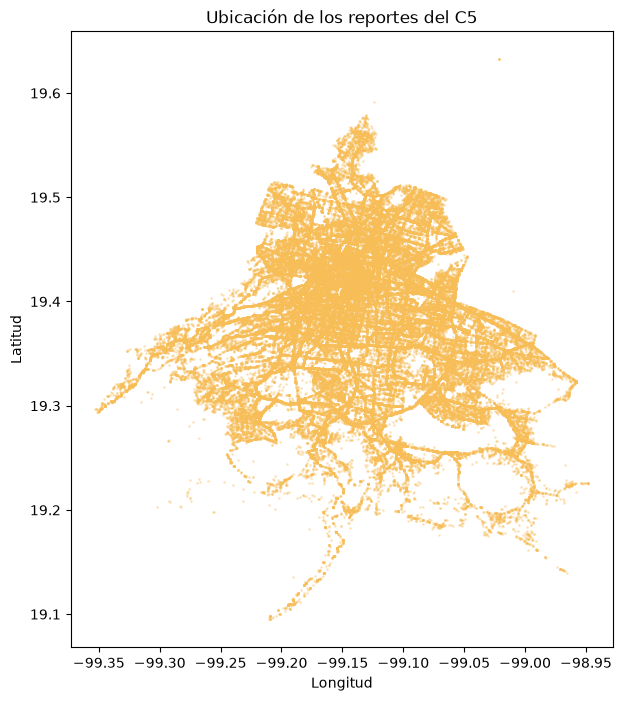

In [48]:
print(df.shape)
plt.figure(figsize=(7, 8))
plt.scatter(df['longitud'], df['latitud'], s=1, alpha=0.3, color='#f7bd56')
plt.xlabel('Longitud')
plt.ylabel('Latitud');
plt.title('Ubicación de los reportes del C5')

Ahora, diferenciando entre aquellas que fueron marcadas con código de cierre F (falsas alarmas) y los demás tipos de cierre de reporte:

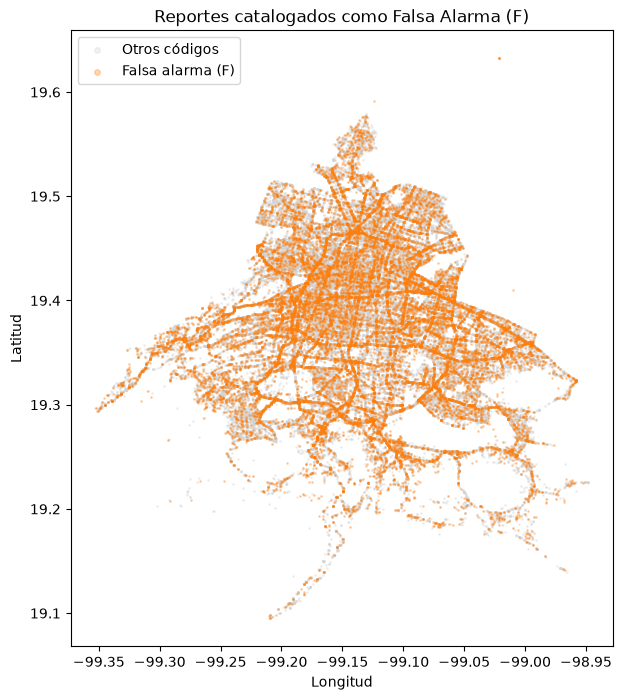

In [49]:
es_falsa = df['codigo_cierre'] == 'F'
plt.figure(figsize=(7, 8))
plt.scatter(df.loc[~es_falsa, 'longitud'], df.loc[~es_falsa, 'latitud'], s=1, alpha=0.3, color='lightgray', label='Otros códigos')
plt.scatter(df.loc[es_falsa, 'longitud'], df.loc[es_falsa, 'latitud'], s=1, alpha=0.3, color='tab:orange', label='Falsa alarma (F)')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('Reportes catalogados como Falsa Alarma (F)')
plt.legend(markerscale=4)
plt.show()

Aquí podemos observar que las falsas alarmas si se concentran sobre avenidas principales. No obstante, no hay una agrupación que se infiera a simple vista.

### Agrupación con K-Means

Hagamos una primer suposición de las agrupaciones con K-Means para observar si naturalmente existen zonas de interés. Correremos este ejercicio con 5, 8 y 12 grupos diferentes (valores de K) para observar el comportamiento de las agrupaciones

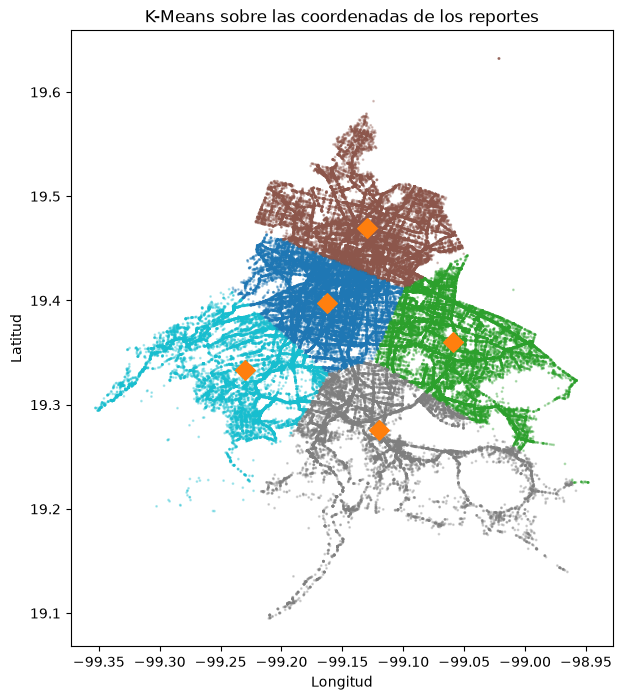

In [50]:
df_numerico = df[['latitud', 'longitud']]

k = 5
kmeans = KMeans(n_clusters=k, init='k-means++', random_state=1, n_init='auto')
kmeans.fit(df_numerico)

y_pred = kmeans.predict(df_numerico)
y_pred

centroids = kmeans.cluster_centers_

plt.figure(figsize=(7, 8))
plt.scatter(df_numerico['longitud'], df_numerico['latitud'], c=y_pred, cmap='tab10', s=1, alpha=0.3)
plt.scatter(centroids[:, 1], centroids[:, 0], color='tab:orange', marker='D', s=100)
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('K-Means sobre las coordenadas de los reportes')
plt.show()

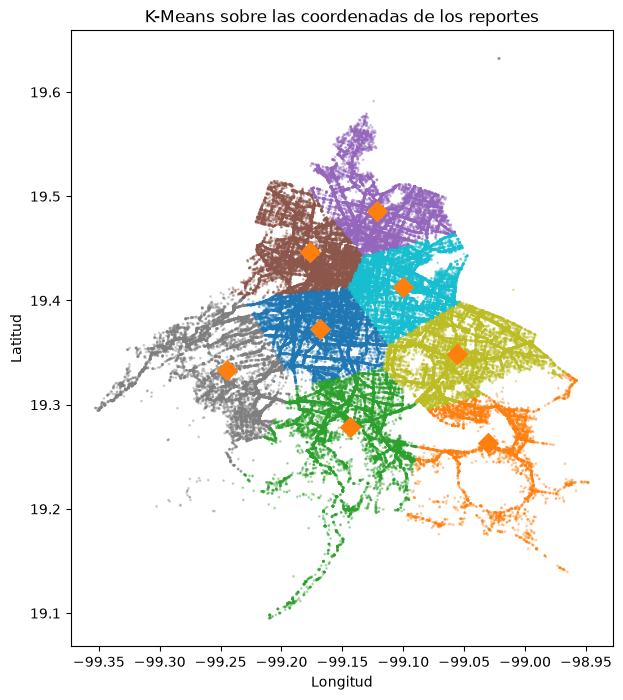

In [51]:
k = 8
kmeans = KMeans(n_clusters=k, init='k-means++', random_state=1, n_init='auto')
kmeans.fit(df_numerico)

y_pred = kmeans.predict(df_numerico)
y_pred

centroids = kmeans.cluster_centers_

plt.figure(figsize=(7, 8))
plt.scatter(df_numerico['longitud'], df_numerico['latitud'], c=y_pred, cmap='tab10', s=1, alpha=0.3)
plt.scatter(centroids[:, 1], centroids[:, 0], color='tab:orange', marker='D', s=100)
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('K-Means sobre las coordenadas de los reportes')
plt.show()

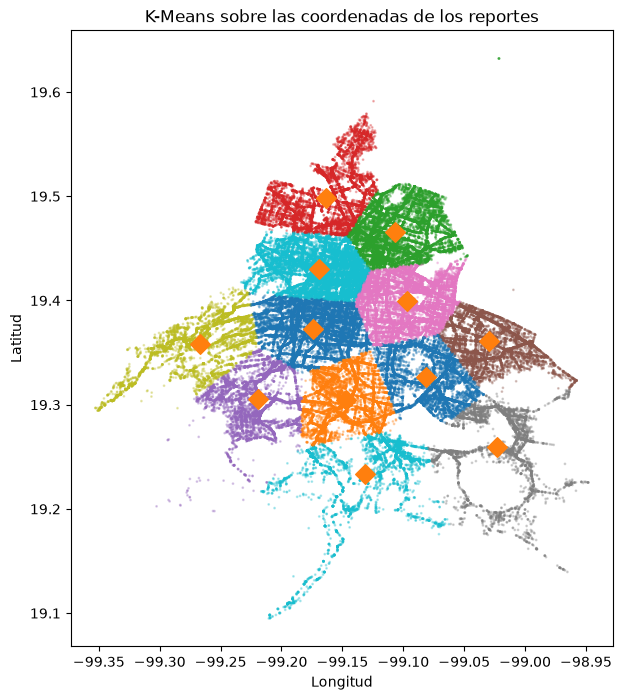

In [52]:
k = 12
kmeans = KMeans(n_clusters=k, init='k-means++', random_state=1, n_init='auto')
kmeans.fit(df_numerico)

y_pred = kmeans.predict(df_numerico)
y_pred

centroids = kmeans.cluster_centers_

plt.figure(figsize=(7, 8))
plt.scatter(df_numerico['longitud'], df_numerico['latitud'], c=y_pred, cmap='tab10', s=1, alpha=0.3)
plt.scatter(centroids[:, 1], centroids[:, 0], color='tab:orange', marker='D', s=100)
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('K-Means sobre las coordenadas de los reportes')
plt.show()

Al correr estas gráficas, vemos que la asignación de grupos comienza a parecerse cada vez más a las demarcaciones de las alcaldías que componen la Ciudad de México, la cual podría ser una agrupación natural para nuestros datos de reportes. Veamos si el número óptimo de agrupaciones se acerca a 16, en número de alcaldías que tiene la CDMX, utilizando el método del codo

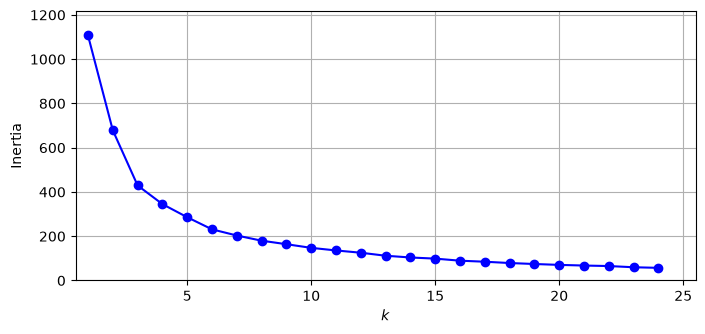

In [53]:
kmeans_per_k = [KMeans(n_clusters=k, n_init='auto', init='k-means++', random_state=42).fit(df_numerico)
                for k in range(1, 25)]
inertias = [model.inertia_ for model in kmeans_per_k]

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 25), inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.xlim(0.5, 25.5)
plt.ylim(0, 1.1 * max(inertias))
plt.grid();

Con el método del codo vemos que nuestro supuesto donde el óptimo se encuentra alrededor del 16 podría ser incorrecto, ya que la inflexión se encuentra alrededor de 6 agrupaciones.

## Uso de DBSCAN

Para poder utilizar DBSCAN, haremos algunas modificaciones a los datos que hemos utilizado hasta el momento:
- Para poder medir de forma adecuada la distancia entre dos puntos, haremos la conversión de latitud y longitud en grados a radianes, con el fin de poder utilizar la medición de haversine.
- Declaramos el radio de la tierra en KM ya que lo utilizaremos al momento de definir el modelo

In [54]:
coordenadas = df[['latitud', 'longitud']].to_numpy()
coordenadas_rad = np.radians(coordenadas)
radio_tierra_km = 6371.0088

Una vez teniendo todo en radianes y conociendo el valor del radio de la tierra, definimos nuestra función para ejecutar el DBSCAN sobre nuestros datos.

In [55]:
def dbscan_geo(coordenadas_radianes, eps_km, min_samples=5):
    eps_rad = eps_km / radio_tierra_km
    modelo = DBSCAN(
        eps=eps_rad,
        min_samples=min_samples,
        metric='haversine',
        algorithm='ball_tree'
    )
    return modelo.fit_predict(coordenadas_radianes)

### Sensibilidad del modelo

Ahora, para observar la sensibilidad del modelo a diferentes valores de eps y de min samples, vamos a simular 12 escenarios:
- 'eps': Distancias máximas para seleccionar vecinos de 100m, 250m, 500m y 1Km
- 'min_samples': número mínimo de puntos en la vecindad de 50, 100 y 250 puntos.

In [56]:
escenarios = [
    (0.1, 50),
    (0.25, 50),
    (0.5, 50),
    (1, 50),
    (0.1, 100),
    (0.25, 100),
    (0.5, 100),
    (1, 100),
    (0.1, 250),
    (0.25, 250),
    (0.5, 250),
    (1, 250)        
]

resultados = {}
filas = []

for eps_km, min_samp in escenarios:
    etiquetas = dbscan_geo(coordenadas_rad, eps_km, min_samp)
    resultados[(eps_km, min_samp)] = etiquetas

    tamaños = pd.Series(etiquetas[etiquetas >= 0]).value_counts()

    filas.append({
        'Distancia entre vecinos (eps)': eps_km,
        'Mínimo de puntos (min_samples)': min_samp,
        'Grupos': len(tamaños),
        'Ruido (%)': round(np.mean(etiquetas == -1) * 100, 1)
    })

comparacion = pd.DataFrame(filas)
comparacion

,Distancia entre vecinos (eps),Mínimo de puntos (min_samples),Grupos,Ruido (%)
0,0.10,50,342,73.5
1,0.25,50,203,19.3
2,0.50,50,18,2.2
3,1.00,50,6,0.2
4,0.10,100,55,93.3
5,0.25,100,198,48.1
6,0.50,100,18,6.8
7,1.00,100,4,1.0
8,0.10,250,0,100.0
9,0.25,250,12,96.4


Con la tabla anterior, vemos que manteniendo el mismo número mínimo de vecinos, pero incrementando la distancia entre ellos, el ruido tiende a disminuir. Por otro lado, si incrementamos el número mínimo de vecinos, pero mantenemos constante la distancia entre ellos, el ruido aumenta.

Además, vemos que la combinación entre los diferentes escenarios que genera menor ruido parece ser el de distancia de 1Km con 50 puntos como mínimo, que reporta un ruido del 0.2% y entrega 6 grupos.

Grafiquemos los escenarios anteriores para visualizarlos:

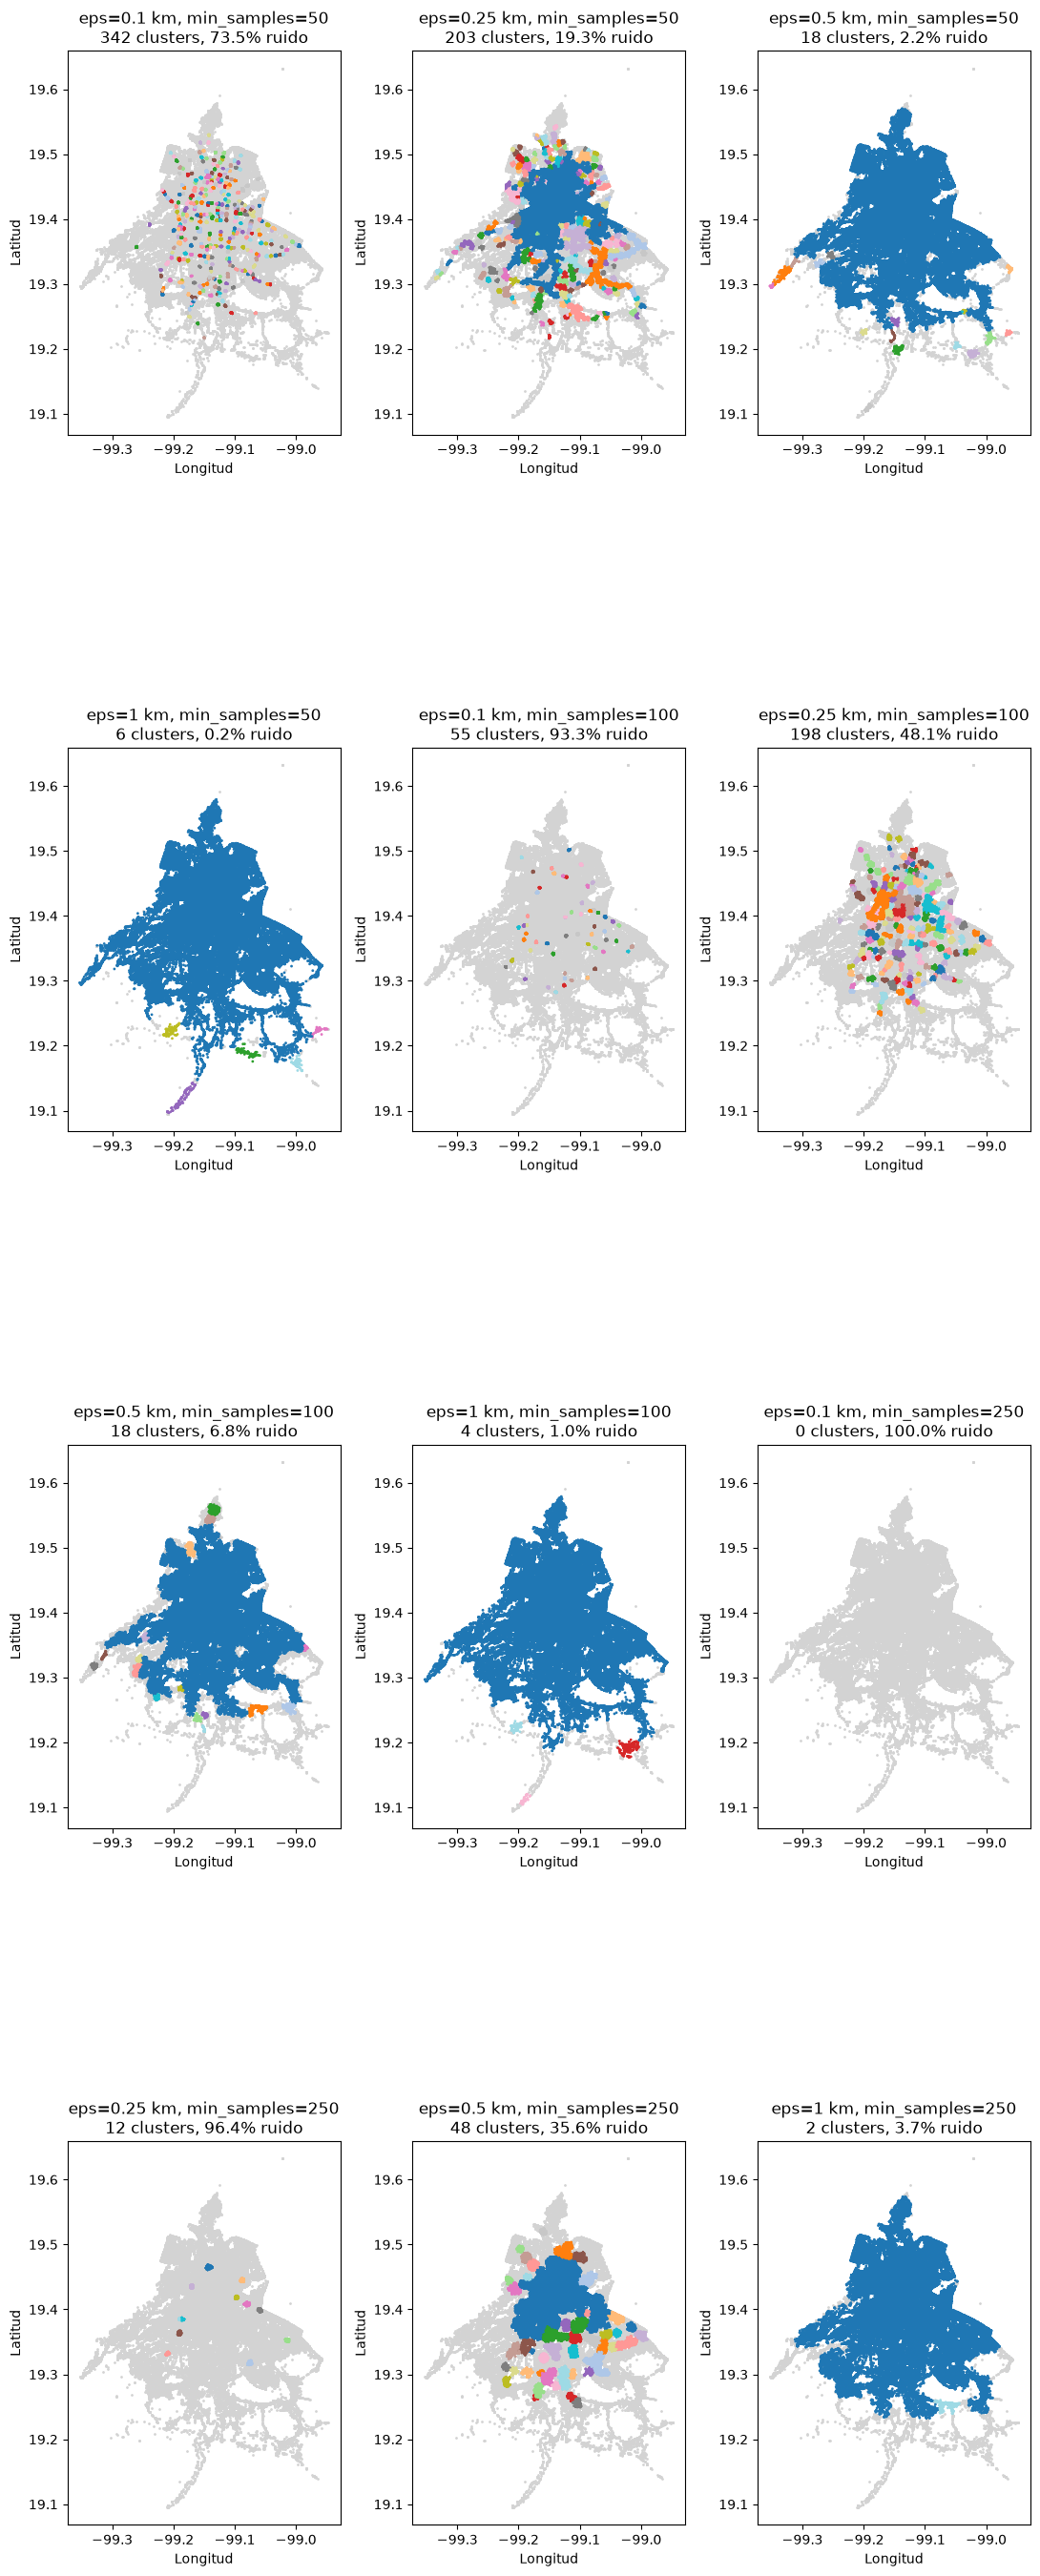

In [57]:
fig, axes = plt.subplots(4, 3, figsize=(11, 30))

for ax, ((eps_km, min_samp), etiquetas) in zip(axes.ravel(), resultados.items()):
    ruido = etiquetas == -1
    ax.scatter(coordenadas[ruido, 1], coordenadas[ruido, 0], color='lightgray', s=1)
    ax.scatter(coordenadas[~ruido, 1], coordenadas[~ruido, 0], c=etiquetas[~ruido] % 20, cmap='tab20', s=1)

    n_grupos = len(set(etiquetas) - {-1})
    ax.set_title(f'eps={eps_km} km, min_samples={min_samp}\n{n_grupos} clusters, {ruido.mean():.1%} ruido')
    ax.set_xlabel('Longitud')
    ax.set_ylabel('Latitud')
    ax.set_aspect(1 / np.cos(np.radians(19.4)))
plt.tight_layout()
plt.show()

En este sentido, vemos que la opción con menor ruido busca agrupar todos los casos en una única mancha dentro del mapa urbano. Por ello, con las visualizaciones, vemos que el caso más útil es aquel con un eps de 0.25Km y un min_samples de 100.

### Interpretación con base en la clusterización propuesta

Vamos a almacenar los clusters para observar las características de cada cluster.

Número de clusters: 198
Reportes dentro de un cluster: 64,486 (51.9%)
Reportes catalogados como ruido: 59,775 (48.1%)


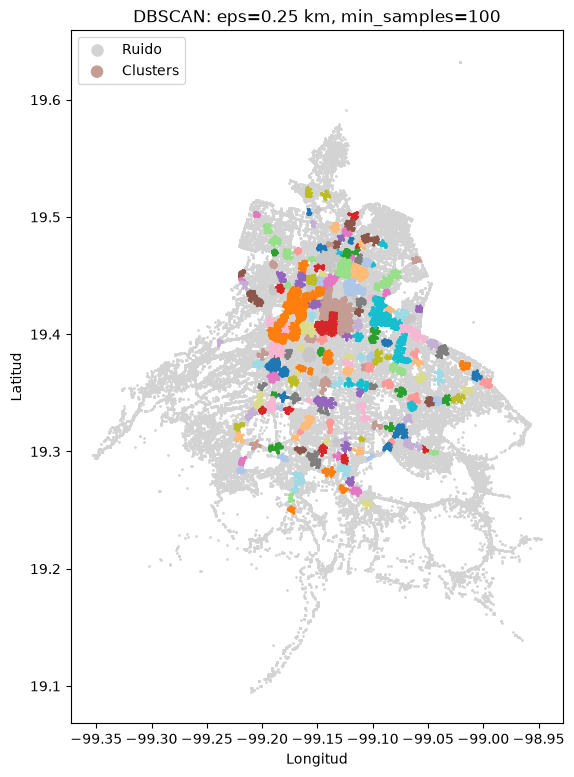

In [ ]:
eps_seleccionado, minimo_seleccionado = 0.25, 100
df['cluster'] = resultados[(eps_seleccionado, minimo_seleccionado)]
df['en_cluster'] = df['cluster'] >= 0

print(f"Número de clusters: {df['cluster'].nunique() - 1}")   # se resta el -1 (ruido)
print(f"Reportes dentro de un cluster: {df['en_cluster'].sum():,} ({df['en_cluster'].mean():.1%})")
print(f"Reportes catalogados como ruido: {(~df['en_cluster']).sum():,} ({(~df['en_cluster']).mean():.1%})")

ruido = ~df['en_cluster']

plt.figure(figsize=(8, 9))
plt.scatter(df.loc[ruido, 'longitud'], df.loc[ruido, 'latitud'], color='lightgray', s=1, label='Ruido')
plt.scatter(df.loc[~ruido, 'longitud'], df.loc[~ruido, 'latitud'], c=df.loc[~ruido, 'cluster'] % 20, cmap='tab20', s=1, label='Clusters')
plt.gca().set_aspect(1 / np.cos(np.radians(19.4)))
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title(f'Clusterización con DBSCAN: eps={eps_seleccionado} km, min_samples={minimo_seleccionado}')
plt.legend(markerscale=8)
plt.show()

In [64]:
resumen = (
    df[df['en_cluster']].groupby('cluster').agg(
        reportes=('folio', 'size'),
        latitud=('latitud', 'mean'),
        longitud=('longitud', 'mean'),
        alcaldia=('alcaldia_inicio', lambda s: s.mode().iloc[0] if s.notna().any() else None),
        pct_F=('codigo_cierre', lambda s: (s == 'F').mean() * 100),
        pct_D=('codigo_cierre', lambda s: (s == 'D').mean() * 100),
        pct_A=('codigo_cierre', lambda s: (s == 'A').mean() * 100),
    )
)

In [67]:
resumen.sort_values('reportes', ascending=False).head(10).round(1)

,reportes,latitud,longitud,alcaldia,pct_F,pct_D,pct_A
cluster,,,,,,,
2,4674,19.4,-99.2,CUAUHTEMOC,19.5,36.4,43.8
11,3482,19.4,-99.1,CUAUHTEMOC,14.1,39.2,45.9
18,2855,19.4,-99.1,VENUSTIANO CARRANZA,20.8,43.7,34.9
46,1526,19.4,-99.1,CUAUHTEMOC,15.3,42.3,42.1
15,1469,19.5,-99.1,CUAUHTEMOC,20.4,37.4,41.5
45,1194,19.5,-99.1,CUAUHTEMOC,13.7,41.5,44.5
38,1100,19.4,-99.1,IZTAPALAPA,18.1,49.5,31.6
1,1047,19.4,-99.1,VENUSTIANO CARRANZA,13.0,42.6,44.0
53,979,19.4,-99.2,BENITO JUAREZ,24.5,37.7,36.9


Si obtenemos los 10 clusters que tienen más reportes, vemos que estos se centran en la Delegación Cuauhtémoc. Esto hace sentido pensando en la cantidad de vías principales que cruzan en esta alcaldía

In [66]:
resumen.sort_values('reportes', ascending=False).tail(10).round(1)

,reportes,latitud,longitud,alcaldia,pct_F,pct_D,pct_A
cluster,,,,,,,
167,87,19.3,-99.1,IZTAPALAPA,20.7,49.4,29.9
172,82,19.5,-99.1,GUSTAVO A. MADERO,15.9,43.9,40.2
187,80,19.3,-99.2,COYOACAN,15.0,48.8,36.2
181,77,19.3,-99.2,TLALPAN,14.3,50.6,33.8
197,71,19.4,-99.2,BENITO JUAREZ,26.8,36.6,36.6
193,67,19.4,-99.1,VENUSTIANO CARRANZA,16.4,50.7,32.8
178,65,19.5,-99.1,GUSTAVO A. MADERO,15.4,44.6,40.0
186,26,19.5,-99.1,GUSTAVO A. MADERO,11.5,69.2,19.2
192,17,19.4,-99.2,MIGUEL HIDALGO,35.3,23.5,41.2


Por el contrario, los clusters que tienen menos reportes se encuentran en alcaldías periféricas, como Tlalpan, Venustiano Carranza o la Gustavo A. Madero. Esto también hace sentido ya que son menos las vías principales que se encuentran en estas alcaldías.

En general, vemos que DBSCAN cataloga como ruido los reportes de la periferia, lo cual hace sentido debido a la cantidad de vialidades que se encuentran en los límites de la CDMX. 

Con esto en mente, observemos como se distribuyen los códigos de cierre en cada uno de los clusters construidos.

In [70]:
ubicacion = df['en_cluster'].map({True: 'Dentro de un cluster', False: 'Fuera de un cluster'})

conteos = pd.crosstab(ubicacion, df['codigo_cierre'])
conteos['Total'] = conteos.sum(axis=1)
print('Conteos de reportes:')
display(conteos)

proporciones = pd.crosstab(ubicacion, df['codigo_cierre'], normalize='index') * 100
print('Porcentaje de reportes:')
display(proporciones.round(1))

Conteos de reportes:


codigo_cierre,A,D,F,I,Total
en_cluster,,,,,
Dentro de un cluster,23587,27509,13010,380,64486
Fuera de un cluster,21602,25454,12209,510,59775


Porcentaje de reportes:


codigo_cierre,A,D,F,I
en_cluster,,,,
Dentro de un cluster,36.6,42.7,20.2,0.6
Fuera de un cluster,36.1,42.6,20.4,0.9


Derivado de las tablas anteriores, vemos que el resultado se encuentra balanceado para todos los códigos de cierre. En particular, para el código "F" que decidimos fuera el código que indica una Falsa Alarma, vemos que se reparte casi al 50% entre lo que el DBSCAN catalogó como ruido y lo que catalogó como parte de un cluster.

Esto se aprecia mejor en la siguiente gráfica:

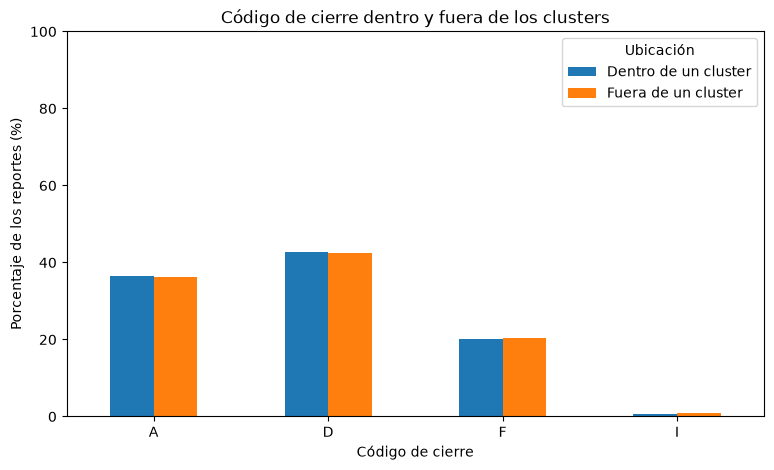

In [71]:
proporciones.T.plot(kind='bar', figsize=(9, 5), rot=0)
plt.xlabel('Código de cierre')
plt.ylabel('Porcentaje de los reportes (%)')
plt.title('Código de cierre dentro y fuera de los clusters')
plt.ylim(0, 100)
plt.legend(title='Ubicación')
plt.show()

Por último, ¿en qué alcaldías es más común que una alerta al C5 se marque como ruido?

In [73]:
(df.groupby('alcaldia_inicio')['en_cluster'].apply(lambda s: (1 - s.mean()) * 100).round(2).sort_values())

alcaldia_inicio
CUAUHTEMOC                 12.85
VENUSTIANO CARRANZA        20.84
BENITO JUAREZ              35.95
IZTACALCO                  36.57
IZTAPALAPA                 44.24
COYOACAN                   45.64
MIGUEL HIDALGO             48.41
GUSTAVO A. MADERO          58.89
TLALPAN                    59.39
ALVARO OBREGON             65.03
AZCAPOTZALCO               67.72
XOCHIMILCO                 71.44
LA MAGDALENA CONTRERAS     79.27
TLAHUAC                    87.88
CUAJIMALPA DE MORELOS     100.00
MILPA ALTA                100.00
Name: en_cluster, dtype: float64

Como observamos en este último cuadro, el 100% de las observaciones de Cuajimalpa y de Milpa Alta fueron catalogados como ruido. Esto es especialmente delicado al momento de hacer otros modelos que sí hagan predicción sobre las falsas alarmas, ya que podríamos ignorar por completo los reportes generados en estas alcaldías.

## Limitaciones del análisis con DBSCAN

DBSCAN nos ayudó en este proceso a identificar zonas donde hay una acumulación de reportes, sin hacer una identificación de si se trata de una falsa alarma o de un reporte verdadero.

En este sentido, observamos que el modelo por si mismo tiene distintas limitantes:
- Dependiendo del valor de eps, la cantidad de clusters generados y aquellos que se catalogan como ruido cambian. Como este valor es un parámetro seleccionado por el analista y no tiene una única verdad, la selección de este parámetro cambia el análisis.
- Igual que con eps, el valor del parámetro de min_samples modifica el ruido que tienen los clusters, pero también es un parámetro que es seleccionado por el analista y su decisión puede aumentar o disminuir el ruido.
- DBSCAN con eps bajos buscaba encadenar los clusters en uno solo, sin embargo, muchas de las veces entregó una única mancha urbana con un ruido muy bajo, lo cual no añade valor al análisis.
- Al ser un proceso no supervisado, no hay forma de controlar si el resultado es correcto o no, ya que no existe una etiqueta previa con la que comparar.
- DBSCAN usa los mismos parámetros en todo el análisis, y como lo vimos al inicio de este notebook, hay puntos más densos por la cantidad de reportes que se hacen sobre un mismo evento y por el número de vialidades que se intersectan hacia el centro de la Ciudad. Esto sesga al modelo cuando toma decisiones de agrupamiento.